In [ ]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
project_path = "/content/drive/MyDrive/Saama/patient-dropout-event-forecasting/patient-dropout-event-forecasting"

In [ ]:
import pandas as pd
X_train = pd.read_csv(f"{project_path}/Phase3/train_x.csv")
y_train = pd.read_csv(f"{project_path}/Phase3/train_y.csv")
X_test = pd.read_csv(f"{project_path}/Phase3/test_x.csv")
y_test = pd.read_csv(f"{project_path}/Phase3/test_y.csv")

In [ ]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)

X_train shape: (9129, 61)
y_train shape: (9129, 3)
X_test shape : (2332, 61)
y_test shape : (2332, 3)


In [ ]:
X_train.head()

,Unnamed: 0,Active Comparator Arm Number,Behavioral intervention Number,Biological intervention Number,Combination Product intervention Number,Device intervention Number,Diagnostic Test intervention Number,Dietary Supplement intervention Number,Drug intervention Number,Experimental Arm Number,...,smiless,sponsors/lead_sponsor/agency_class,study_design_info/allocation,study_design_info/intervention_model,study_design_info/intervention_model_description,study_design_info/masking,study_design_info/masking_description,study_design_info/masking_num,study_design_info/primary_purpose,study_type
0,NCT00099359,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,3.0,...,['CC1=CN([C@H]2C[C@H](N=[N+]=[N-])[C@@H](CO)O2...,NIH,Randomized,Parallel Assignment,NaN,None (Open Label),NaN,0.0,Prevention,Interventional
1,NCT01618162,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,...,NaN,Industry,Randomized,Parallel Assignment,NaN,"Double (Participant, Investigator)",NaN,2.0,Treatment,Interventional
2,NCT03433755,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0,...,NaN,Industry,Randomized,Parallel Assignment,Participants will be screened for this study a...,"Quadruple (Participant, Care Provider, Investi...",The dose frequencies of Q2W and QM will not be...,4.0,Treatment,Interventional
3,NCT00843024,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,3.0,...,['CNS(=O)(=O)CC1=CC=C2NC=C(CCN(C)C)C2=C1'],Industry,Randomized,Parallel Assignment,NaN,"Double (Participant, Investigator)",NaN,2.0,Treatment,Interventional
4,NCT00357877,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,['ClC1=CC=C(NC(=N)NC(=N)NCCCCCCNC(=N)NC(=N)NC2...,Other,Randomized,Parallel Assignment,NaN,"Quadruple (Participant, Care Provider, Investi...",NaN,4.0,Prevention,Interventional


In [ ]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9129 entries, 0 to 9128
Data columns (total 61 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   Unnamed: 0                                        9129 non-null   object 
 1   Active Comparator Arm Number                      9072 non-null   float64
 2   Behavioral intervention Number                    9129 non-null   float64
 3   Biological intervention Number                    9129 non-null   float64
 4   Combination Product intervention Number           9129 non-null   float64
 5   Device intervention Number                        9129 non-null   float64
 6   Diagnostic Test intervention Number               9129 non-null   float64
 7   Dietary Supplement intervention Number            9129 non-null   float64
 8   Drug intervention Number                          9129 non-null   float64
 9   Experimental Arm Nu

In [ ]:
X_train.describe()

,Active Comparator Arm Number,Behavioral intervention Number,Biological intervention Number,Combination Product intervention Number,Device intervention Number,Diagnostic Test intervention Number,Dietary Supplement intervention Number,Drug intervention Number,Experimental Arm Number,Genetic intervention Number,...,Radiation intervention Number,Sham Comparator Arm Number,enrollment,ipd_info_type-Analytic Code,ipd_info_type-Clinical Study Report (CSR),ipd_info_type-Informed Consent Form (ICF),ipd_info_type-Statistical Analysis Plan (SAP),ipd_info_type-Study Protocol,number_of_arms,study_design_info/masking_num
count,9072.000000,9129.000000,9129.000000,9129.000000,9129.000000,9129.000000,9129.000000,9129.000000,9072.000000,9129.000000,...,9129.00000,9072.000000,9129.000000,675.000000,675.000000,675.00000,675.000000,675.000000,9072.000000,9107.000000
mean,0.502535,0.018184,0.276810,0.006463,0.049951,0.000767,0.010625,2.008106,1.319996,0.001534,...,0.01665,0.009369,718.097272,0.057778,0.749630,0.42963,0.977778,0.992593,2.301367,1.799715
std,0.724696,0.177929,0.814089,0.109085,0.283806,0.037731,0.138845,1.582849,0.992312,0.046784,...,0.16598,0.096347,2213.253962,0.233496,0.433548,0.49539,0.147515,0.085811,1.132889,1.629628
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.00000,0.000000,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,...,0.00000,0.000000,118.000000,0.000000,0.500000,0.00000,1.000000,1.000000,2.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,1.000000,0.000000,...,0.00000,0.000000,307.000000,0.000000,1.000000,0.00000,1.000000,1.000000,2.000000,2.000000
75%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,2.000000,0.000000,...,0.00000,0.000000,637.000000,0.000000,1.000000,1.00000,1.000000,1.000000,3.000000,4.000000
max,8.000000,3.000000,13.000000,3.000000,3.000000,3.000000,4.000000,30.000000,17.000000,3.000000,...,4.00000,1.000000,59666.000000,1.000000,1.000000,1.00000,1.000000,1.000000,24.000000,4.000000


In [ ]:
y_train.head()

,Unnamed: 0,droupout_rate,Y/N
0,NCT00099359,0.107781,1
1,NCT01618162,0.167816,1
2,NCT03433755,0.008264,1
3,NCT00843024,0.168081,1
4,NCT00357877,0.056968,1


In [ ]:
print(y_train.columns)

Index(['Unnamed: 0', 'droupout_rate', 'Y/N'], dtype='object')


In [ ]:
y_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9129 entries, 0 to 9128
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     9129 non-null   object 
 1   droupout_rate  9129 non-null   float64
 2   Y/N            9129 non-null   int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 214.1+ KB


In [ ]:
missing = X_train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing

,0
study_design_info/masking_description,8812
study_design_info/intervention_model_description,8781
ipd_info_type-Informed Consent Form (ICF),8454
ipd_info_type-Statistical Analysis Plan (SAP),8454
ipd_info_type-Study Protocol,8454
ipd_info_type-Clinical Study Report (CSR),8454
ipd_info_type-Analytic Code,8454
oversight_info/is_fda_regulated_device,6731
oversight_info/is_fda_regulated_drug,6710
patient_data/sharing_ipd,6086


In [ ]:
missing_percentage = (X_train.isnull().sum() / len(X_train)) * 100
missing_percentage = (
    missing_percentage[missing_percentage > 0]
    .sort_values(ascending=False))
missing_percentage

,0
study_design_info/masking_description,96.527550
study_design_info/intervention_model_description,96.187972
ipd_info_type-Informed Consent Form (ICF),92.605981
ipd_info_type-Statistical Analysis Plan (SAP),92.605981
ipd_info_type-Study Protocol,92.605981
ipd_info_type-Clinical Study Report (CSR),92.605981
ipd_info_type-Analytic Code,92.605981
oversight_info/is_fda_regulated_device,73.732063
oversight_info/is_fda_regulated_drug,73.502027
patient_data/sharing_ipd,66.666667


In [ ]:
X_train.dtypes.value_counts()

,count
object,32
float64,29


In [ ]:
X_train.duplicated().sum()

np.int64(0)

In [ ]:
y_train["droupout_rate"].describe()

,droupout_rate
count,9129.000000
mean,0.237613
std,0.287094
min,0.000000
25%,0.043478
50%,0.124929
75%,0.296037
max,1.000000


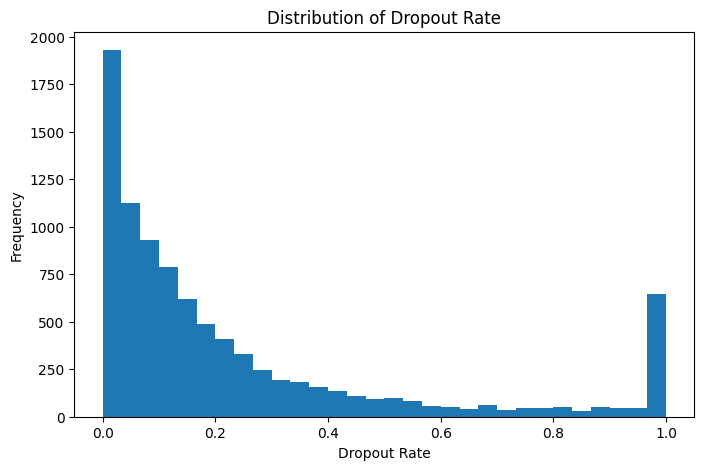

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.hist(y_train["droupout_rate"], bins=30)
plt.xlabel("Dropout Rate")
plt.ylabel("Frequency")
plt.title("Distribution of Dropout Rate")
plt.show()